# Weather Data

## Data Source

This dataset is a potential source of external information to integrate into our project. The data was obtained from the [Open-Meteo Historical Forecast API](https://open-meteo.com/en/docs/gfs-api?timezone=America%2FChicago&latitude=41.85&longitude=-87.65&time_mode=time_interval&start_date=2026-01-01&end_date=2026-10-21&api_mode=historical_forecast&hourly=&minutely_15=rain,temperature_2m,snowfall,sunshine_duration,weather_code,is_day&daily=weather_code), using weather data for Chicago.

## Data description

- time
- weather_code (wmo code)
- temperature_2m_max (°C)
- temperature_2m_min (°C)
- rain_sum (mm)
- snowfall_sum (cm)
- showers_sum (mm)
- wind_speed_10m_max (km/h)
- precipitation_sum (mm)
- sunrise (iso8601)
- sunset (iso8601)
- daylight_duration (s)

## Objective

The objective of this preliminary analysis is to characterize the dataset, assess the variability and relevance of the available meteorological variables.

In [1]:
# Import libraries
import pandas as pd
import numpy as np
from collections import Counter
import matplotlib.pyplot as plt

In [5]:
# Reading files
data_folder = './raw/'
weather22 = pd.read_csv(data_folder + 'weather_2022.csv', skiprows=3)
weather23 = pd.read_csv(data_folder + 'weather_2023.csv', skiprows=3)
weather24 = pd.read_csv(data_folder + 'weather_2024.csv', skiprows=3)
weather25 = pd.read_csv(data_folder + 'weather_2025.csv', skiprows=3)

### Sanity checks:

In [6]:
# Sanity check: print the shape of the dataframes
# We have yearly reports, so we expect 365 rows
print(f'For 2022 we have reports from: {weather22.shape[0]} days')
print(f'For 2023 we have reports from: {weather23.shape[0]} days')
print(f'For 2024 we have reports from: {weather24.shape[0]} days')
print(f'For 2025 we have reports from: {weather25.shape[0]} days')

For 2022 we have reports from: 365 days
For 2023 we have reports from: 365 days
For 2024 we have reports from: 366 days
For 2025 we have reports from: 365 days


In [7]:
# Do we have NA values?
print(f'For 2022 we have: NA values:\n{weather22.isna().sum()}\n')
print(f'For 2023 we have: NA values:\n{weather23.isna().sum()}\n')
print(f'For 2024 we have: NA values:\n{weather24.isna().sum()}\n')
print(f'For 2025 we have: NA values:\n{weather25.isna().sum()}\n')

For 2022 we have: NA values:
time                         0
weather_code (wmo code)      0
temperature_2m_max (°C)      0
temperature_2m_min (°C)      0
sunrise (iso8601)            0
sunset (iso8601)             0
rain_sum (mm)                0
showers_sum (mm)             0
snowfall_sum (cm)            0
wind_speed_10m_max (km/h)    0
precipitation_sum (mm)       0
daylight_duration (s)        0
dtype: int64

For 2023 we have: NA values:
time                         0
weather_code (wmo code)      0
temperature_2m_max (°C)      0
temperature_2m_min (°C)      0
sunrise (iso8601)            0
sunset (iso8601)             0
rain_sum (mm)                0
showers_sum (mm)             0
snowfall_sum (cm)            0
wind_speed_10m_max (km/h)    0
precipitation_sum (mm)       0
daylight_duration (s)        0
dtype: int64

For 2024 we have: NA values:
time                         0
weather_code (wmo code)      0
temperature_2m_max (°C)      0
temperature_2m_min (°C)      0
sunrise (iso8601)

### Data exploration:

In [8]:
# Print columns 
weather22.columns

Index(['time', 'weather_code (wmo code)', 'temperature_2m_max (°C)',
       'temperature_2m_min (°C)', 'sunrise (iso8601)', 'sunset (iso8601)',
       'rain_sum (mm)', 'showers_sum (mm)', 'snowfall_sum (cm)',
       'wind_speed_10m_max (km/h)', 'precipitation_sum (mm)',
       'daylight_duration (s)'],
      dtype='str')

In [9]:
# Rename columns:
new_names ={'weather_code (wmo code)':'weather_code',
            'sunrise (iso8601)':'sunrise',
            'daylight_duration (s)':'daylight_duration',
            'temperature_2m_max (°C)':'temperature_2m_max',
            'temperature_2m_min (°C)':'temperature_2m_min',
            'sunset (iso8601)':'sunset',
            'rain_sum (mm)':'rain_sum',
            'snowfall_sum (cm)':'snowfall_sum',
            'wind_speed_10m_max (km/h)': 'wind_speed_10m_max',
            'showers_sum (mm)': 'showers_sum',
            'precipitation_sum (mm)': 'precipitation_sum'
                              }

In [10]:
weather22 = weather22.rename(columns= new_names)
weather23 = weather22.rename(columns= new_names)
weather24 = weather22.rename(columns= new_names)
weather25 = weather22.rename(columns= new_names)

In [11]:
weather22

,time,weather_code,temperature_2m_max,temperature_2m_min,sunrise,sunset,rain_sum,showers_sum,snowfall_sum,wind_speed_10m_max,precipitation_sum,daylight_duration
0,01/01/2022,75,3.6,-1.9,2022-01-01T08:18,2022-01-01T17:30,3.6,0,5.32,36.6,11.2,33123.81
1,02/01/2022,75,-1.7,-9.4,2022-01-02T08:18,2022-01-02T17:31,2.6,0,4.34,34.4,8.8,33170.56
2,03/01/2022,1,-5.6,-12.7,2022-01-03T08:18,2022-01-03T17:32,0.0,0,0.00,26.0,0.0,33221.36
3,04/01/2022,3,0.1,-6.4,2022-01-04T08:18,2022-01-04T17:33,0.0,0,0.00,24.6,0.0,33276.72
4,05/01/2022,3,0.0,-12.8,2022-01-05T08:18,2022-01-05T17:34,0.0,0,0.00,44.8,0.0,33336.53
...,...,...,...,...,...,...,...,...,...,...,...,...
360,27/12/2022,45,-4.0,-12.0,2022-12-27T08:17,2022-12-27T17:26,0.0,0,0.00,23.0,0.0,32936.50
361,28/12/2022,3,6.2,-4.0,2022-12-28T08:17,2022-12-28T17:27,0.0,0,0.00,25.9,0.0,32962.27
362,29/12/2022,3,13.3,5.7,2022-12-29T08:17,2022-12-29T17:27,0.0,0,0.00,24.7,0.0,32992.41
363,30/12/2022,3,13.3,0.3,2022-12-30T08:17,2022-12-30T17:28,0.0,0,0.00,24.0,0.0,33027.19


In [12]:
# Incorporate weather code meaning 
weather_code = {
	"0": "Clear sky",
	"1": "Mainly clear",
	"2": "Partly cloudy",
	"3": "Overcast",
	"45": "Fog",
	"48": "Depositing rime fog",
	"51": "Light drizzle",
	"53": "Moderate drizzle",
	"55": "Dense drizzle",
	"56": "Light freezing drizzle",
	"57": "Dense freezing drizzle",
	"61": "Slight rain",
	"63": "Moderate rain",
	"65": "Heavy rain",
	"66": "Light freezing rain",
	"67": "Heavy freezing rain",
	"71": "Slight snowfall",
	"73": "Moderate snowfall",
	"75": "Heavy snowfall",
	"77": "Snow grains",
	"80": "Slight rain showers",
	"81": "Moderate rain showers",
	"82": "Violent rain showers",
	"85": "Slight snow showers",
	"86": "Heavy snow showers",
	"95": "Thunderstorm",
	"96": "Thunderstorm with slight hail",
	"97": "Heavy thunderstorm",
	"99": "Thunderstorm with heavy hail"
}

In [13]:
# Add weather code meaning
weather22["weather"] = weather22["weather_code"].astype(str).map(weather_code)
weather23["weather"] = weather23["weather_code"].astype(str).map(weather_code)
weather24["weather"] = weather24["weather_code"].astype(str).map(weather_code)
weather25["weather"] = weather25["weather_code"].astype(str).map(weather_code)

In [14]:
weather22

,time,weather_code,temperature_2m_max,temperature_2m_min,sunrise,sunset,rain_sum,showers_sum,snowfall_sum,wind_speed_10m_max,precipitation_sum,daylight_duration,weather
0,01/01/2022,75,3.6,-1.9,2022-01-01T08:18,2022-01-01T17:30,3.6,0,5.32,36.6,11.2,33123.81,Heavy snowfall
1,02/01/2022,75,-1.7,-9.4,2022-01-02T08:18,2022-01-02T17:31,2.6,0,4.34,34.4,8.8,33170.56,Heavy snowfall
2,03/01/2022,1,-5.6,-12.7,2022-01-03T08:18,2022-01-03T17:32,0.0,0,0.00,26.0,0.0,33221.36,Mainly clear
3,04/01/2022,3,0.1,-6.4,2022-01-04T08:18,2022-01-04T17:33,0.0,0,0.00,24.6,0.0,33276.72,Overcast
4,05/01/2022,3,0.0,-12.8,2022-01-05T08:18,2022-01-05T17:34,0.0,0,0.00,44.8,0.0,33336.53,Overcast
...,...,...,...,...,...,...,...,...,...,...,...,...,...
360,27/12/2022,45,-4.0,-12.0,2022-12-27T08:17,2022-12-27T17:26,0.0,0,0.00,23.0,0.0,32936.50,Fog
361,28/12/2022,3,6.2,-4.0,2022-12-28T08:17,2022-12-28T17:27,0.0,0,0.00,25.9,0.0,32962.27,Overcast
362,29/12/2022,3,13.3,5.7,2022-12-29T08:17,2022-12-29T17:27,0.0,0,0.00,24.7,0.0,32992.41,Overcast
363,30/12/2022,3,13.3,0.3,2022-12-30T08:17,2022-12-30T17:28,0.0,0,0.00,24.0,0.0,33027.19,Overcast


In [15]:
# Time format (as team convention): 2014-08-07
time_22 = [f'{time.split("/")[2]}-{time.split("/")[1]}-{time.split("/")[0]}' for time in weather22.time]
time_23 = [f'{time.split("/")[2]}-{time.split("/")[1]}-{time.split("/")[0]}' for time in weather23.time]
time_24 = [f'{time.split("/")[2]}-{time.split("/")[1]}-{time.split("/")[0]}' for time in weather24.time]
time_25 = [f'{time.split("/")[2]}-{time.split("/")[1]}-{time.split("/")[0]}' for time in weather25.time]

In [16]:
weather22["time"] = time_22
weather23["time"] = time_23
weather24["time"] = time_24
weather25["time"] = time_25

In [17]:
weather22

,time,weather_code,temperature_2m_max,temperature_2m_min,sunrise,sunset,rain_sum,showers_sum,snowfall_sum,wind_speed_10m_max,precipitation_sum,daylight_duration,weather
0,2022-01-01,75,3.6,-1.9,2022-01-01T08:18,2022-01-01T17:30,3.6,0,5.32,36.6,11.2,33123.81,Heavy snowfall
1,2022-01-02,75,-1.7,-9.4,2022-01-02T08:18,2022-01-02T17:31,2.6,0,4.34,34.4,8.8,33170.56,Heavy snowfall
2,2022-01-03,1,-5.6,-12.7,2022-01-03T08:18,2022-01-03T17:32,0.0,0,0.00,26.0,0.0,33221.36,Mainly clear
3,2022-01-04,3,0.1,-6.4,2022-01-04T08:18,2022-01-04T17:33,0.0,0,0.00,24.6,0.0,33276.72,Overcast
4,2022-01-05,3,0.0,-12.8,2022-01-05T08:18,2022-01-05T17:34,0.0,0,0.00,44.8,0.0,33336.53,Overcast
...,...,...,...,...,...,...,...,...,...,...,...,...,...
360,2022-12-27,45,-4.0,-12.0,2022-12-27T08:17,2022-12-27T17:26,0.0,0,0.00,23.0,0.0,32936.50,Fog
361,2022-12-28,3,6.2,-4.0,2022-12-28T08:17,2022-12-28T17:27,0.0,0,0.00,25.9,0.0,32962.27,Overcast
362,2022-12-29,3,13.3,5.7,2022-12-29T08:17,2022-12-29T17:27,0.0,0,0.00,24.7,0.0,32992.41,Overcast
363,2022-12-30,3,13.3,0.3,2022-12-30T08:17,2022-12-30T17:28,0.0,0,0.00,24.0,0.0,33027.19,Overcast


In [ ]:
# Add months?
#months = [time.split("/")[1] for time in weather22.time]
#weather22["month"] = months

# Daylight duration in hours?
# weather22["daylight_duration_hrs"] = weather22["daylight_duration"] / 60 ** 2

In [ ]:
# Save data as separeted files
#save_folder = '../raw/weather/'
#weather22.to_csv(save_folder + "weather_2022_c.csv", index=False)
#weather23.to_csv(save_folder + "weather_2023_c.csv", index=False)
#weather24.to_csv(save_folder + "weather_2024_c.csv", index=False)
#weather25.to_csv(save_folder + "weather_2025_c.csv", index=False)

In [ ]:
# Concatenate data in a single df
weather22_25 = pd.concat([weather22, weather23, weather24, weather25], ignore_index=True)

In [21]:
# Save data as one single file
save_folder = './clean/'
weather22_25.to_csv(save_folder + "weather_2022_2025.csv", index=False)

In [59]:
weather22_25

,time,weather_code,temperature_2m_max,temperature_2m_min,sunrise,sunset,rain_sum,showers_sum,snowfall_sum,wind_speed_10m_max,precipitation_sum,daylight_duration,weather
0,2022-01-01,75,3.6,-1.9,2022-01-01T08:18,2022-01-01T17:30,3.6,0,5.32,36.6,11.2,33123.81,Heavy snowfall
1,2022-01-02,75,-1.7,-9.4,2022-01-02T08:18,2022-01-02T17:31,2.6,0,4.34,34.4,8.8,33170.56,Heavy snowfall
2,2022-01-03,1,-5.6,-12.7,2022-01-03T08:18,2022-01-03T17:32,0.0,0,0.00,26.0,0.0,33221.36,Mainly clear
3,2022-01-04,3,0.1,-6.4,2022-01-04T08:18,2022-01-04T17:33,0.0,0,0.00,24.6,0.0,33276.72,Overcast
4,2022-01-05,3,0.0,-12.8,2022-01-05T08:18,2022-01-05T17:34,0.0,0,0.00,44.8,0.0,33336.53,Overcast
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,2022-12-27,45,-4.0,-12.0,2022-12-27T08:17,2022-12-27T17:26,0.0,0,0.00,23.0,0.0,32936.50,Fog
1456,2022-12-28,3,6.2,-4.0,2022-12-28T08:17,2022-12-28T17:27,0.0,0,0.00,25.9,0.0,32962.27,Overcast
1457,2022-12-29,3,13.3,5.7,2022-12-29T08:17,2022-12-29T17:27,0.0,0,0.00,24.7,0.0,32992.41,Overcast
1458,2022-12-30,3,13.3,0.3,2022-12-30T08:17,2022-12-30T17:28,0.0,0,0.00,24.0,0.0,33027.19,Overcast


# Exploratory analysis

In [24]:
print(f'Out of the {len(weather_code)} weather categories, 2022 broadcast data shows {len(np.unique(weather22["weather"]))}')
print(f'Out of the {len(weather_code)} weather categories, 2022 broadcast data shows {len(np.unique(weather23["weather"]))}')
print(f'Out of the {len(weather_code)} weather categories, 2022 broadcast data shows {len(np.unique(weather24["weather"]))}')
print(f'Out of the {len(weather_code)} weather categories, 2022 broadcast data shows {len(np.unique(weather25["weather"]))}')

Out of the 29 weather categories, 2022 broadcast data shows 18
Out of the 29 weather categories, 2022 broadcast data shows 18
Out of the 29 weather categories, 2022 broadcast data shows 18
Out of the 29 weather categories, 2022 broadcast data shows 18


In [ ]:
# Most frequent weather status trhoughout the year: 
# weather22["weather"].value_counts()

In [219]:
weather_by_month = weather22.groupby("month")["weather"].value_counts()

In [220]:
weather_by_month

month  weather          
01     Overcast             17
       Heavy snowfall        4
       Moderate snowfall     4
       Partly cloudy         3
       Mainly clear          2
                            ..
12     Moderate snowfall     2
       Moderate rain         1
       Light drizzle         1
       Clear sky             1
       Heavy snowfall        1
Name: count, Length: 103, dtype: int64

In [221]:
weather22.columns

Index(['time', 'weather_code', 'daylight_duration', 'temperature_2m_max',
       'temperature_2m_min', 'rain_sum', 'snowfall_sum', 'wind_speed_10m_max',
       'sunrise', 'sunset', 'weather', 'month', 'daylight_duration_hrs'],
      dtype='str')

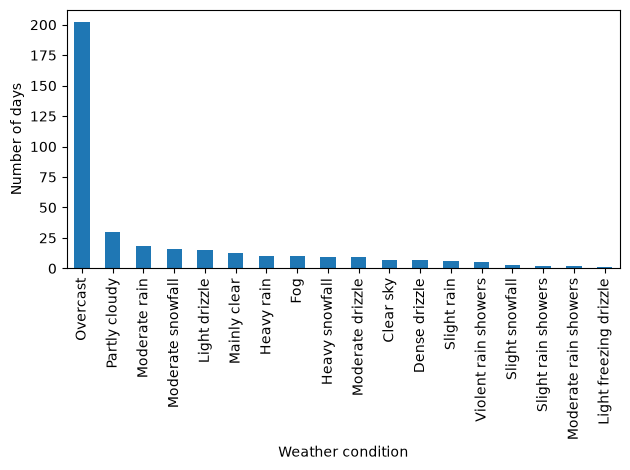

In [222]:
# Through the year:
weather22["weather"].value_counts().plot(kind="bar")
plt.xlabel("Weather condition")
plt.ylabel("Number of days")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

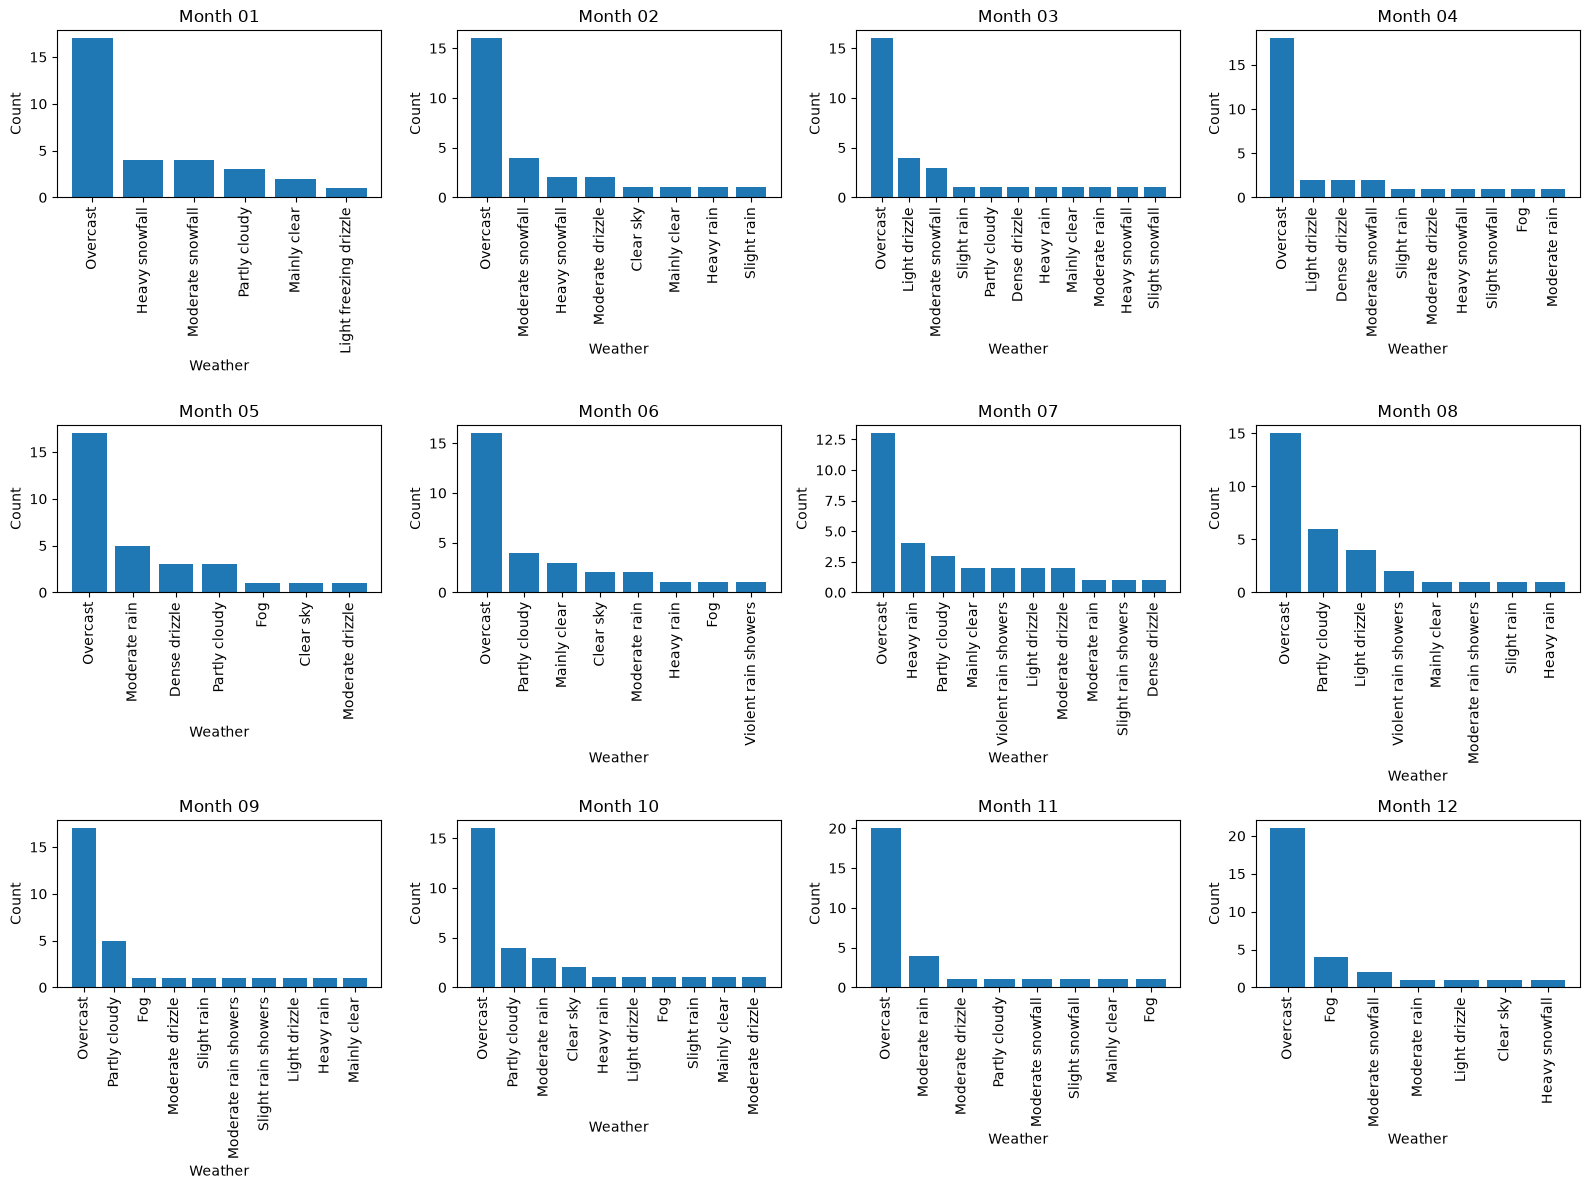

In [223]:
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
for ax, (month, data) in zip(axes.flat, weather_by_month.groupby(level=0)):
    counts = data.droplevel(0)
    ax.bar(counts.index, counts.values)
    ax.set_title(f"Month {month}")
    ax.set_xlabel("Weather")
    ax.set_ylabel("Count")
    ax.tick_params(axis="x", rotation=90)

plt.tight_layout()
plt.show()

### What could we do with this data?
- Since we aim to use bike-share data as a *social sensor*, meteorological events can be incorporated as external events that may disrupt or influence mobility patterns across the city.
- Weather conditions may be important predictors of bike-share usage. Therefore, incorporating meteorological variables into the dataset is essential to assess their contribution to explaining changes in cycling patterns. To quantify their effects and distinguish them from other factors, we should integrate the weather and bike-share data and develop a predictive model.
- Do we want to save: sunrise (iso8601), sunset (iso8601) or daylight_duration (s) ? Maybe, if this can allow us to explain late trips during days with more daylight duration as in summer, having trips at night is not as rare in summer as it is in december. 